<a href="https://colab.research.google.com/github/Samlat-stack/digit-prediction/blob/main/digit_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)
Pixel min: 0 | max: 255
Images per digit: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


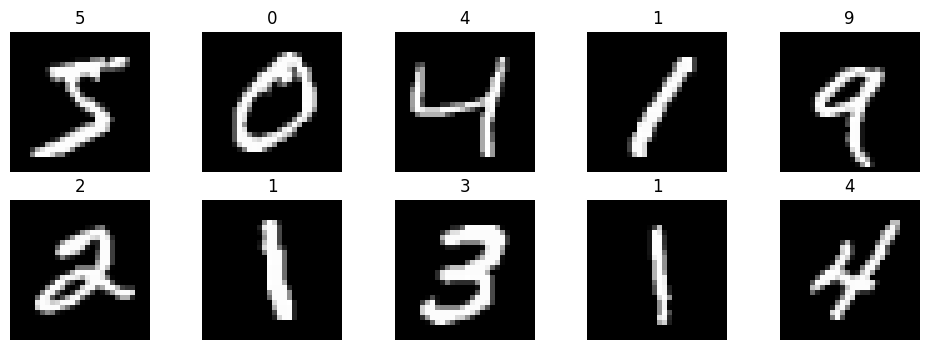

In [13]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)
print("Pixel min:", X_train.min(), "| max:", X_train.max())
print("Images per digit:", np.bincount(y_train))

# show the first 10 images with their labels
plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

In [14]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Pixel min:", X_train.min(), "| max:", X_train.max())

Pixel min: 0.0 | max: 1.0


In [15]:
from sklearn.linear_model import LogisticRegression

X_train_flat = X_train.reshape(len(X_train), 784)
X_test_flat = X_test.reshape(len(X_test), 784)
print(X_train_flat.shape)

lr = LogisticRegression(max_iter=200)
lr.fit(X_train_flat[:10000], y_train[:10000])

print("Dumb baseline: about 0.11")
print("Logistic regression:", round(lr.score(X_test_flat, y_test), 3))

(60000, 784)
Dumb baseline: about 0.11
Logistic regression: 0.905


In [16]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(X_train, y_train, epochs=10, validation_split=0.1)

test_loss, test_acc = model.evaluate(X_test, y_test)
print("Dumb baseline: 0.11 | Logistic regression: 0.905")
print("Neural network test accuracy:", round(test_acc, 3))

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9211 - loss: 0.2789 - val_accuracy: 0.9657 - val_loss: 0.1237
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9638 - loss: 0.1228 - val_accuracy: 0.9742 - val_loss: 0.0942
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9751 - loss: 0.0846 - val_accuracy: 0.9752 - val_loss: 0.0879
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9807 - loss: 0.0623 - val_accuracy: 0.9775 - val_loss: 0.0800
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9855 - loss: 0.0488 - val_accuracy: 0.9792 - val_loss: 0.0760
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9881 - loss: 0.0381 - val_accuracy: 0.9793 - val_loss: 0.0740
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9909 - loss: 0.0293 - val_accuracy: 0.9783 - val_loss: 0.0773
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9925 - loss: 0.0247 - 

In [17]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

probs = model.predict(X_test)
preds = np.argmax(probs, axis=1)

print(classification_report(y_test, preds))

cm = confusion_matrix(y_test, preds)
digits = [str(i) for i in range(10)]
pd.DataFrame(cm, index=digits, columns=digits)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.98      0.99      0.99      1135
           2       0.98      0.97      0.97      1032
           3       0.98      0.97      0.97      1010
           4       0.98      0.98      0.98       982
           5       0.97      0.97      0.97       892
           6       0.98      0.99      0.98       958
           7       0.97      0.98      0.98      1028
           8       0.96      0.97      0.97       974
           9       0.98      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



,0,1,2,3,4,5,6,7,8,9
0,969,1,1,1,0,1,2,1,4,0
1,0,1128,2,0,0,1,2,2,0,0
2,6,4,998,1,2,0,3,6,11,1
3,0,0,5,976,0,10,0,3,11,5
4,1,1,4,0,959,0,5,5,1,6
5,1,1,1,10,1,868,4,0,5,1
6,3,2,0,1,2,5,945,0,0,0
7,1,4,6,2,0,0,0,1008,3,4
8,2,3,1,3,2,7,1,3,948,4
9,2,6,0,2,15,3,1,6,2,972


# Handwritten Digit Classification (MNIST)

## Goal
Classify 28x28 grayscale images of handwritten digits into 10 classes (0-9).

## Data and preparation
- Dataset: MNIST, 60,000 training and 10,000 test images.
- Classes are roughly balanced (5,421 to 6,742 per digit). Always guessing
  the most common digit (1) would be right about 11% of the time.
- Pixel values (0-255) were scaled to 0-1 by dividing by 255.

## Models and results
| Model                                        | Test accuracy |
|----------------------------------------------|---------------|
| Dumb baseline (always guess "1")             | about 0.11    |
| Logistic regression (flattened, 10k images)  | 0.905         |
| Neural network (128 ReLU units, 10 epochs)   | 0.979         |

Note: logistic regression was trained on 10,000 images to save time,
while the neural network used about 54,000 (10% held back for validation),
so part of the gap may come from the extra data.

## Where the model struggles
- Digit 9 has the lowest recall (0.96). It is most often